# Hari 1, Sesi 3: Variabel Dummy dan Uji Asumsi Klasik

**Durasi:** 90 menit

Dua bagian besar. Pertama, variabel dummy untuk data kategorikal (gender,
status, periode krisis). Kedua, empat uji asumsi klasik yang wajib bisa
dijalankan dan ditafsirkan: multikolinearitas, heteroskedastisitas,
normalitas, dan autokorelasi.

Pola kerja yang dipakai sepanjang sesi:

1. Estimasi model OLS.
2. Jalankan uji diagnostik.
3. Kalau asumsi dilanggar, tangani dengan alat yang sesuai: robust
   standard error (HC3) untuk heteroskedastisitas, HAC untuk
   autokorelasi, dan buang atau gabungkan variabel untuk
   multikolinearitas.
4. Baca hasil sesuai koreksi yang dipilih. HC3/HAC mempertahankan
   koefisien OLS, tetapi standard error dan p-value dapat berubah.



**Posisi dalam alur workshop.** Setelah bentuk model tepat (Sesi 2),
sekarang periksa apakah hasilnya layak dipercaya. Sesi berikutnya
mengganti jenis variabel Y dari kontinu ke kategorikal.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita memeriksa dummy dan asumsi model. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah pola antarfitur dan pola residual sebelum membaca hasil uji.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


## 1. Variabel dummy

Data `latihan_dummy_1.csv`: gaji, pengalaman, gender, dan status pernikahan
30 karyawan. Dua variabel terakhir kategorikal, jadi harus diubah ke angka
dulu. Ini yang di EViews dilakukan otomatis lewat fitur dummy.



<!-- kamus_variabel:latihan_dummy_1.csv -->

### Kenali data: Gaji dan karakteristik pekerja

**Data:** `data/latihan_dummy_1.csv`. **Satu baris:** satu pekerja pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `No` | `No` | Nomor urut pekerja. | Nomor identitas | Penanda, bukan besaran ekonomi |
| `GAJI` | `gaji` | Besarnya gaji pekerja. | Uang; skala/periode gaji tidak dirinci | Y: target |
| `PENGALAMAN` | `pengalaman` | Lama pengalaman kerja pekerja. | Satuan waktu tidak dirinci sumber | X: penjelas |
| `GENDER` | `gender` | Kategori gender yang dicatat dalam berkas. | Teks: Pria atau Wanita | X: penjelas |
| `STATUS` | `status` | Status perkawinan pekerja. | Teks: Menikah atau Lajang | X: penjelas |

Kategori teks diubah menjadi dummy 0/1 saat praktik; kelompok acuan dijelaskan pada bagian pembentukan dummy.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `dummy_pria` | Indikator kategori Pria; kelompok selain Pria menjadi acuan. | 1 = Pria; 0 = selain Pria |
| `dummy_menikah` | Indikator status Menikah; kelompok selain Menikah menjadi acuan. | 1 = Menikah; 0 = selain Menikah |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

gaji = pd.read_csv(URL_DATA + "latihan_dummy_1.csv")
gaji = gaji.rename(
    columns={
        "GAJI": "gaji",
        "PENGALAMAN": "pengalaman",
        "GENDER": "gender",
        "STATUS": "status",
    }
)

gaji.head()

,No,gaji,pengalaman,gender,status
0,1,8.5,3,Pria,Menikah
1,2,7.2,2,Wanita,Lajang
2,3,15.1,8,Pria,Menikah
3,4,9.8,4,Pria,Lajang
4,5,11.5,5,Wanita,Menikah


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [3]:
gaji["gender"].value_counts(), gaji["status"].value_counts()



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

### Dummy trap dan cara menghindarinya

Kalau dua kategori (Pria/Wanita) dibuat dua kolom dummy, jumlah keduanya
selalu 1. Kolom itu menjadi kombinasi linear sempurna dengan konstanta,
dan OLS tidak bisa diestimasi. Solusinya: selalu buang satu kategori
sebagai basis.

`pd.get_dummies(..., drop_first=True)` melakukan ini otomatis, tapi
kategori yang dibuang mengikuti urutan alfabet. Supaya kontrol tetap di
tangan kita, di sini kolom dummy dibuat eksplisit. Basisnya: Wanita dan
Lajang.



In [4]:
gaji_d = gaji.copy()
gaji_d["dummy_pria"] = (gaji_d["gender"] == "Pria").astype(int)
gaji_d["dummy_menikah"] = (gaji_d["status"] == "Menikah").astype(int)
gaji_d.head()


,No,gaji,pengalaman,gender,status,dummy_pria,dummy_menikah
0,1,8.5,3,Pria,Menikah,1,1
1,2,7.2,2,Wanita,Lajang,0,0
2,3,15.1,8,Pria,Menikah,1,1
3,4,9.8,4,Pria,Lajang,1,0
4,5,11.5,5,Wanita,Menikah,0,1


In [5]:
sampel_model_dummy_mentah = gaji_d[["gaji", "dummy_pria", "dummy_menikah"]].dropna()
X_model_dummy_mentah = sampel_model_dummy_mentah[["dummy_pria", "dummy_menikah"]]
y_model_dummy_mentah = sampel_model_dummy_mentah["gaji"]

model_dummy_mentah = LinearRegression()
model_dummy_mentah.fit(X_model_dummy_mentah, y_model_dummy_mentah)


LinearRegression()

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [6]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_dummy_mentah = sm.OLS(
    y_model_dummy_mentah,
    sm.add_constant(X_model_dummy_mentah, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_dummy_mentah.summary())


                            OLS Regression Results                            
Dep. Variable:                   gaji   R-squared:                       0.538
Model:                            OLS   Adj. R-squared:                  0.504
Method:                 Least Squares   F-statistic:                     15.71
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           2.98e-05
Time:                        17:42:18   Log-Likelihood:                -81.444
No. Observations:                  30   AIC:                             168.9
Df Residuals:                      27   BIC:                             173.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         8.0957      1.314      6.161

In [7]:
sampel_model_dummy = gaji_d[
    ["gaji", "pengalaman", "dummy_pria", "dummy_menikah"]
].dropna()
X_model_dummy = sampel_model_dummy[["pengalaman", "dummy_pria", "dummy_menikah"]]
y_model_dummy = sampel_model_dummy["gaji"]

model_dummy = LinearRegression()
model_dummy.fit(X_model_dummy, y_model_dummy)


LinearRegression()

### Dummy membedakan kelompok pada kondisi yang sama

Panel kiri memperlihatkan gaji mentah menurut gender. Untuk panel kanan,
buat dua profil dengan pengalaman yang sama dan status lajang. Profil
kedua hanya mengubah `dummy_pria` dari 0 menjadi 1.

In [8]:
profil_wanita = pd.DataFrame({
    "pengalaman": np.linspace(gaji["pengalaman"].min(), gaji["pengalaman"].max(), 40),
    "dummy_pria": 0,
    "dummy_menikah": 0,
})
profil_pria = profil_wanita.copy()
profil_pria["dummy_pria"] = 1

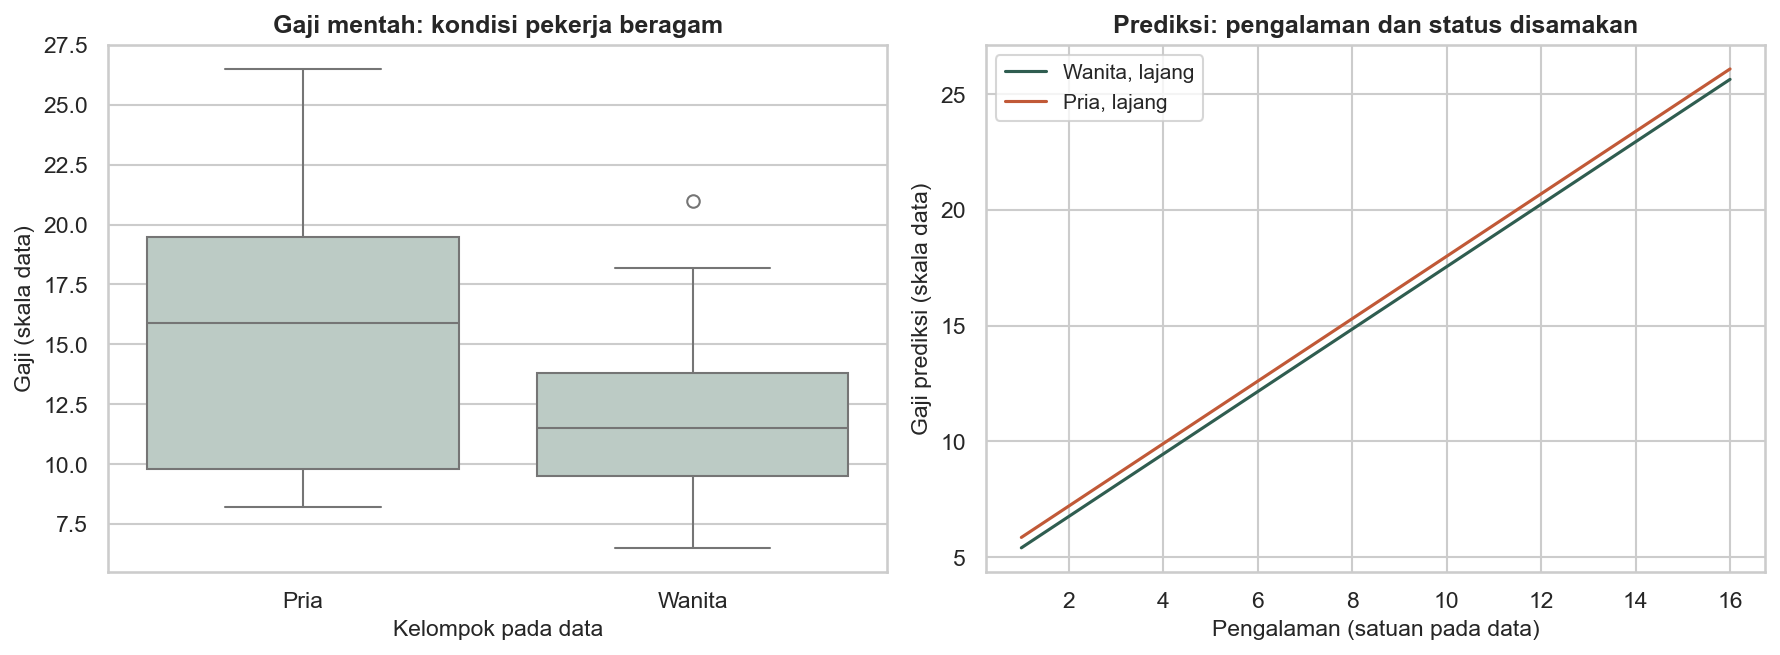

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=gaji, x="gender", y="gaji", color="#B9CEC6", ax=axes[0])
axes[0].set(xlabel="Kelompok pada data", ylabel="Gaji (skala data)", title="Gaji mentah: kondisi pekerja beragam")
axes[1].plot(profil_wanita["pengalaman"], model_dummy.predict(profil_wanita), label="Wanita, lajang", color="#2F5D50")
axes[1].plot(profil_pria["pengalaman"], model_dummy.predict(profil_pria), label="Pria, lajang", color="#C15937")
axes[1].set(xlabel="Pengalaman (satuan pada data)", ylabel="Gaji prediksi (skala data)", title="Prediksi: pengalaman dan status disamakan")
axes[1].legend()
plt.tight_layout()
plt.show()

**Cara membaca:** garis tengah kotak kiri adalah median gaji mentah.
Kotak mencakup 50 persen pengamatan tengah; garis di luar kotak dan titik
terpisah menunjukkan sebaran menurut aturan boxplot. Panel kanan memakai
prediksi dengan status lajang pada kedua kelompok. Jarak vertikal kedua
garis adalah perbedaan prediksi dari dummy gender pada model ini, bukan
selisih median mentah atau bukti sebab akibat.

### Lihat hasil model: Gaji (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

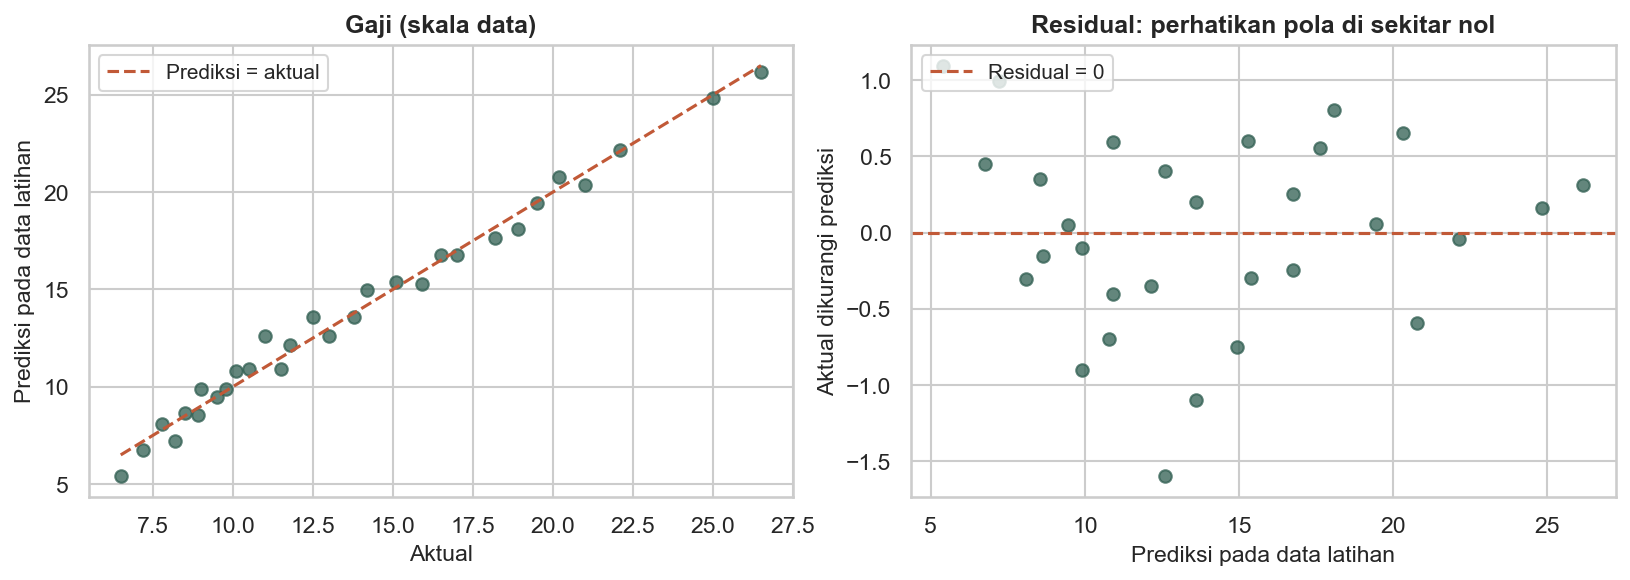

In [10]:
prediksi_visual = model_dummy.predict(X_model_dummy)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_dummy, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_dummy.min(), y_model_dummy.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Gaji (skala data)")
axes[1].scatter(prediksi_visual, y_model_dummy - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [11]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_dummy = sm.OLS(
    y_model_dummy,
    sm.add_constant(X_model_dummy, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_dummy.summary())


                            OLS Regression Results                            
Dep. Variable:                   gaji   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.985
Method:                 Least Squares   F-statistic:                     641.7
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           1.74e-24
Time:                        17:42:19   Log-Likelihood:                -28.253
No. Observations:                  30   AIC:                             64.51
Df Residuals:                      26   BIC:                             70.11
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.0548      0.265     15.287

### Menafsirkan dummy

Basis di sini adalah Wanita dan Lajang. Di model mentah (tanpa kontrol),
`dummy_pria` = +3,35 dan `dummy_menikah` = +7,05, keduanya signifikan.
Setelah pengalaman kerja dikontrol, keduanya mengecil mendekati nol dan
tidak lagi signifikan.

Ini pelajaran penting: koefisien dummy adalah selisih antar kelompok
SETELAH variabel lain dikontrol. Perbedaan mentah di data ini sebagian
besar dijelaskan oleh pengalaman kerja yang berbeda antar kelompok.
Model mana yang dilaporkan? Tergantung pertanyaan penelitian: untuk
membandingkan perbedaan mentah antar kelompok, pakai model tanpa
kontrol; untuk membandingkan kelompok dengan pengalaman yang setara,
pakai model terkontrol. Yang tidak boleh: melaporkan model mentah lalu
bicara seolah pengalaman sudah dikontrol.

Intersep = rata-rata gaji kelompok basis saat pengalaman = 0.
Di laporan, selalu sebut kategori basisnya secara eksplisit.



## 2. Dummy untuk peristiwa: krisis ekonomi

`latihan_dummy_2.csv`: PDB dan investasi tahunan, dengan dummy `KRISIS`
bernilai 1 di tahun krisis. Model: `pdb ~ investasi + suku_bunga + krisis`.



<!-- kamus_variabel:latihan_dummy_2.csv -->

### Kenali data: PDB, investasi, dan krisis

**Data:** `data/latihan_dummy_2.csv`. **Satu baris:** satu tahun pada contoh ekonomi simulasi.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun` | `tahun` | Tahun kalender pengamatan. | Tahun | Penanda waktu |
| `PDB` | `pdb` | Indikator PDB yang menjadi target contoh. | Skala PDB tidak dirinci sumber | Y: target |
| `INVESTASI` | `investasi` | Besarnya investasi pada periode tersebut. | Skala investasi tidak dirinci sumber | X: penjelas |
| `SUKU_BUNGA` | `suku_bunga` | Tingkat bunga pada periode tersebut. | Persen dalam konteks latihan | X: penjelas |
| `KRISIS` | `krisis` | Penanda apakah pengamatan termasuk periode krisis pada data. | 1 = krisis; 0 = bukan krisis | X: penjelas |

PDB pada nama kolom tidak otomatis berarti pertumbuhan PDB. Berkas tidak menyertakan metadata skala level/pertumbuhan; jangan menyamakannya dengan PDB_Growth World Bank.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [12]:
krisis = pd.read_csv(URL_DATA + "latihan_dummy_2.csv")
krisis = krisis.rename(
    columns={
        "Tahun": "tahun",
        "PDB": "pdb",
        "INVESTASI": "investasi",
        "SUKU_BUNGA": "suku_bunga",
        "KRISIS": "krisis",
    }
)

krisis.head()

,tahun,pdb,investasi,suku_bunga,krisis
0,1986,5.9,22,8.0,0
1,1987,4.9,21,8.5,0
2,1988,5.8,23,7.5,0
3,1989,7.5,24,7.0,0
4,1990,7.2,25,7.2,0


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [13]:
sampel_model_krisis = krisis[["pdb", "investasi", "suku_bunga", "krisis"]].dropna()
X_model_krisis = sampel_model_krisis[["investasi", "suku_bunga", "krisis"]]
y_model_krisis = sampel_model_krisis["pdb"]

In [14]:
model_krisis = LinearRegression()
model_krisis.fit(X_model_krisis, y_model_krisis)

koefisien_model_krisis = pd.Series(model_krisis.coef_, index=X_model_krisis.columns)
koefisien_model_krisis.loc["Intercept"] = model_krisis.intercept_

prediksi_model_krisis = pd.Series(
    model_krisis.predict(X_model_krisis), index=y_model_krisis.index
)
residu_model_krisis = y_model_krisis - prediksi_model_krisis


**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [15]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_krisis = sm.OLS(
    y_model_krisis,
    sm.add_constant(X_model_krisis, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_krisis.summary())


                            OLS Regression Results                            
Dep. Variable:                    pdb   R-squared:                       0.850
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     49.03
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           7.70e-11
Time:                        17:42:19   Log-Likelihood:                -52.814
No. Observations:                  30   AIC:                             113.6
Df Residuals:                      26   BIC:                             119.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.8133      4.752      3.749      0.0

Koefisien `krisis` adalah perbedaan rata-rata PDB pada tahun krisis
dibanding tahun normal, setelah investasi dan suku bunga dikontrol.
Kalau negatif dan signifikan: krisis berdampak buruk, sesuai dugaan.



### Coba sendiri (5 menit)

Dengan model dummy di bagian 1, prediksi gaji untuk Wanita yang belum
menikah dengan pengalaman 5 tahun.

Tulis di sel di bawah, baru buka jawabannya.



In [16]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

Kedua dummy bernilai nol, jadi gajinya = intersep + 1,3489 x 5.
Hasilnya sekitar 10,80 (satuan sama dengan kolom gaji).

</details>



Bagian dummy selesai. Mulai di sini, kita kembali ke model OLS dengan
variabel kontinu dan memeriksa satu per satu asumsi klasiknya.

## 3. Uji multikolinearitas

Multikolinearitas = korelasi tinggi antar variabel penjelas. Akibatnya
standard error membengkak, t-statistik mengecil, dan koefisien jadi tidak
stabil. Deteksinya dengan VIF (Variance Inflation Factor).

Aturan praktis: VIF di atas 10 menandakan masalah serius. Di antara 5 dan
10, perlu kehati-hatian.



<!-- kamus_variabel:latihan_multikolinieritas_1.csv -->

### Kenali data: Harga dan ukuran rumah

**Data:** `data/latihan_multikolinieritas_1.csv`. **Satu baris:** satu rumah pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `No` | `No` | Nomor rumah/pengamatan. | Nomor identitas | Penanda, bukan besaran ekonomi |
| `HARGA` | `harga` | Harga jual rumah. | Uang; skala tidak dirinci | Y: target |
| `LUAS_BANGUNAN` | `luas_bangunan` | Luas fisik bangunan rumah. | Satuan luas tidak dirinci sumber | X: penjelas |
| `LUAS_TANAH` | `luas_tanah` | Luas tanah tempat rumah berada. | Satuan luas tidak dirinci sumber | X: penjelas |
| `JML_KAMAR` | `jml_kamar` | Jumlah kamar pada rumah. | Kamar | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

rumah = pd.read_csv(URL_DATA + "latihan_multikolinieritas_1.csv")
rumah = rumah.rename(
    columns={
        "HARGA": "harga",
        "LUAS_BANGUNAN": "luas_bangunan",
        "LUAS_TANAH": "luas_tanah",
        "JML_KAMAR": "jml_kamar",
    }
)

rumah.head()

,No,harga,luas_bangunan,luas_tanah,jml_kamar
0,1,8.5,100,120,3
1,2,7.0,90,110,2
2,3,15.0,180,200,4
3,4,9.8,110,150,3
4,5,12.0,150,160,4


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [18]:
X = sm.add_constant(rumah[["luas_bangunan", "luas_tanah", "jml_kamar"]])
# Kolom 0 adalah konstanta; kolom 1 sampai 3 adalah variabel penjelas.
vif_bangunan = variance_inflation_factor(X.values, 1)
vif_tanah = variance_inflation_factor(X.values, 2)
vif_kamar = variance_inflation_factor(X.values, 3)

vif = pd.DataFrame(
    {
        "variabel": ["luas_bangunan", "luas_tanah", "jml_kamar"],
        "VIF": [vif_bangunan, vif_tanah, vif_kamar],
    }
)
vif

,variabel,VIF
0,luas_bangunan,64.215353
1,luas_tanah,44.609819
2,jml_kamar,13.666960


### Lihat mengapa dua fitur bisa membawa informasi yang hampir sama

Sebelum menafsirkan VIF, bandingkan pola antarfitur. Warna membantu kita melihat pasangan yang bergerak bersama.

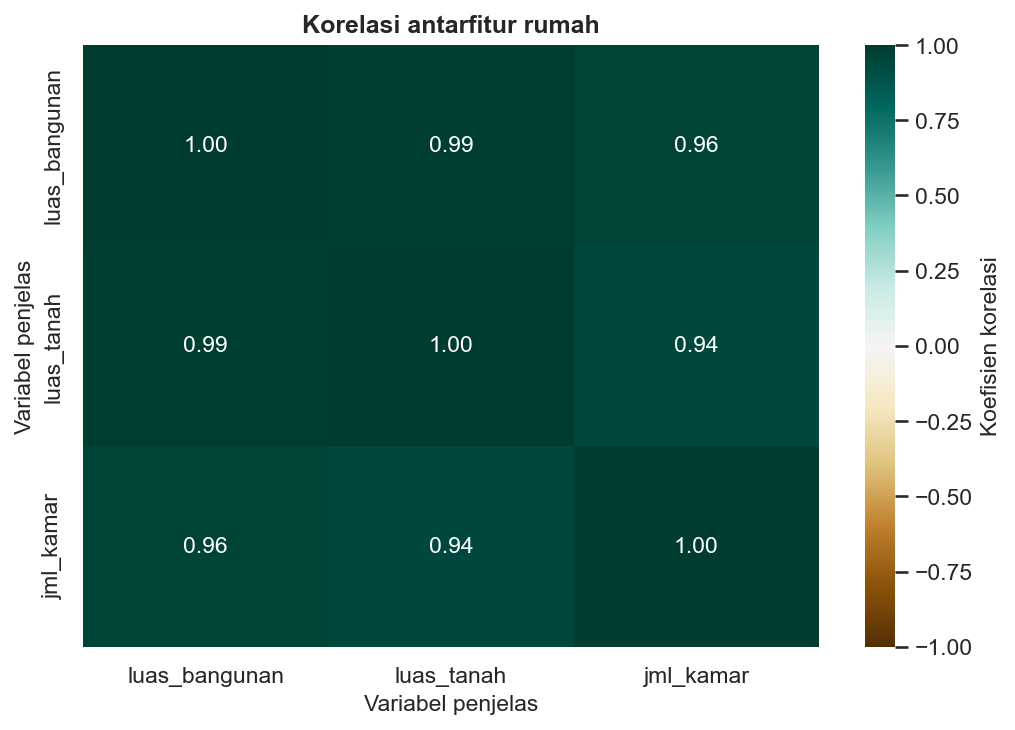

In [19]:
korelasi_fitur = rumah[["luas_bangunan", "luas_tanah", "jml_kamar"]].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(korelasi_fitur, annot=True, fmt=".2f", cbar_kws={"label": "Koefisien korelasi"}, vmin=-1, vmax=1, cmap="BrBG", ax=ax)
ax.set_title("Korelasi antarfitur rumah")
ax.set_xlabel("Variabel penjelas")
ax.set_ylabel("Variabel penjelas")
plt.tight_layout()
plt.show()

**Cara membaca:** Angka mendekati 1 atau −1 menunjukkan hubungan linear yang kuat antarfitur. Itu membantu menjelaskan VIF, tetapi warna bukan keputusan untuk langsung menghapus variabel. Berikutnya baca VIF bersama tujuan model.

Kalau `luas_bangunan` dan `luas_tanah` punya VIF besar, lihat korelasinya.
Di data ini korelasinya 0,99. Sebagai patokan, korelasi antar penjelas
di atas 0,8 sudah patut dicurigai.



In [20]:
rumah[["luas_bangunan", "luas_tanah", "jml_kamar"]].corr()


,luas_bangunan,luas_tanah,jml_kamar
luas_bangunan,1.000000,0.988472,0.961860
luas_tanah,0.988472,1.000000,0.944611
jml_kamar,0.961860,0.944611,1.000000


In [21]:
sampel_model_rumah = rumah[
    ["harga", "luas_bangunan", "luas_tanah", "jml_kamar"]
].dropna()
X_model_rumah = sampel_model_rumah[["luas_bangunan", "luas_tanah", "jml_kamar"]]
y_model_rumah = sampel_model_rumah["harga"]

model_rumah = LinearRegression()
model_rumah.fit(X_model_rumah, y_model_rumah)


LinearRegression()

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [22]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_rumah = sm.OLS(
    y_model_rumah,
    sm.add_constant(X_model_rumah, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(f"R2 = {model_rumah.score(X_model_rumah, y_model_rumah):.4f}")
print(uji_model_rumah.summary())


R2 = 0.9959
                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     2129.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           3.33e-31
Time:                        17:42:20   Log-Likelihood:                -8.5969
No. Observations:                  30   AIC:                             25.19
Df Residuals:                      26   BIC:                             30.80
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -1.4925      0.27

Perhatikan kombinasi yang khas: R kuadrat tinggi dan uji F signifikan,
tapi koefisien satu per satu tidak signifikan. Ini gejala klasik
multikolinearitas. Solusinya: buang salah satu variabel yang redundan,
gabungkan keduanya, atau perbesar sampel.



### Coba sendiri (5 menit)

Hitung ulang VIF setelah `luas_tanah` dibuang. Apakah masalahnya selesai?

Tulis di sel di bawah, baru buka jawabannya.



In [23]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

VIF tersisa: `luas_bangunan` 13,4 dan `jml_kamar` 13,4. Membaik dari
64 dan 45, tapi masih di atas 10 karena korelasinya 0,96. Langkah
lanjut: pertimbangkan hanya memakai satu di antaranya.

</details>



## 4. Uji heteroskedastisitas

Varians residual yang berubah-ubah sepanjang nilai X. Dampaknya: standard
error OLS salah, sehingga uji t dan uji F tidak valid. Gejalanya sering
terlihat di scatter residual vs fitted.

Data `hetero_3.csv`: harga rumah dijelaskan luas bangunan, jumlah kamar,
dan skor lokasi. Dugaan di soal: variasi harga jauh lebih besar untuk
rumah luas di lokasi premium.



<!-- kamus_variabel:hetero_3.csv -->

### Kenali data: Harga dan karakteristik rumah

**Data:** `data/hetero_3.csv`. **Satu baris:** satu rumah pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Harga` | `harga` | Harga jual rumah. | Ratusan juta rupiah | Y: target |
| `Luas` | `luas` | Luas bangunan rumah. | Meter persegi (m²) | X: penjelas |
| `Kamar` | `kamar` | Jumlah kamar tidur. | Kamar | X: penjelas |
| `Lokasi` | `lokasi` | Skor kelayakan/kualitas lokasi rumah; bukan kode alamat. | Skor 1 sampai 10 | X: penjelas |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `abs_resid` | Nilai mutlak selisih harga aktual dan prediksi untuk uji Glejser. | Sama dengan satuan Harga |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [24]:
hunian = pd.read_csv(URL_DATA + "hetero_3.csv")
hunian = hunian.rename(
    columns={"Harga": "harga", "Luas": "luas", "Kamar": "kamar", "Lokasi": "lokasi"}
)

hunian.head()

,harga,luas,kamar,lokasi
0,4.88,100,2,6
1,8.21,150,3,8
2,5.55,110,3,6
3,12.13,200,4,9
4,4.52,95,2,5


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [25]:
sampel_model_h = hunian[["harga", "luas", "kamar", "lokasi"]].dropna()
X_model_h = sampel_model_h[["luas", "kamar", "lokasi"]]
y_model_h = sampel_model_h["harga"]

In [26]:
model_h = LinearRegression()
model_h.fit(X_model_h, y_model_h)

koefisien_model_h = pd.Series(model_h.coef_, index=X_model_h.columns)
koefisien_model_h.loc["Intercept"] = model_h.intercept_

prediksi_model_h = pd.Series(model_h.predict(X_model_h), index=y_model_h.index)
residu_model_h = y_model_h - prediksi_model_h


**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [27]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_h = sm.OLS(
    y_model_h,
    sm.add_constant(X_model_h, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_h.summary())


                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                     2744.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           7.39e-52
Time:                        17:42:20   Log-Likelihood:                -19.685
No. Observations:                  50   AIC:                             47.37
Df Residuals:                      46   BIC:                             55.02
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.3774      0.437     -3.149      0.0

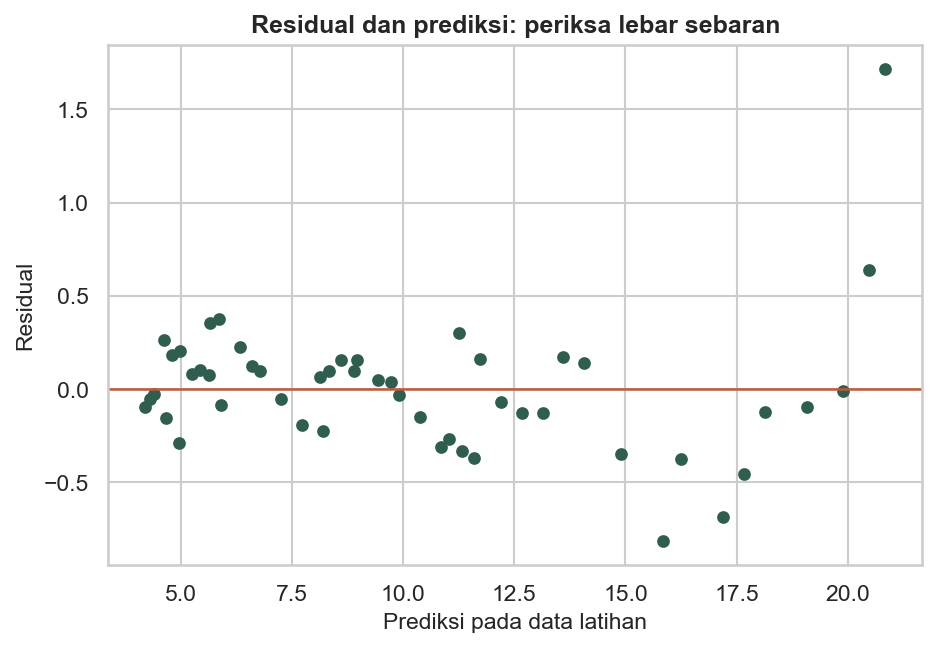

In [28]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(prediksi_model_h, residu_model_h, color="#2F5D50", s=26)
ax.axhline(0, color="#C15937", lw=1.2)
ax.set_xlabel("Prediksi pada data latihan")
ax.set_ylabel("Residual")
ax.set_title("Residual dan prediksi: periksa lebar sebaran")
plt.show()


**Baca grafik sebelum lanjut:** Baca posisi titik terhadap nol dan perubahan lebar sebarannya. Pola melengkung atau bentuk kipas menjadi alasan memeriksa spesifikasi atau asumsi, bukan langsung mengubah koefisien.

Kalau titik-titik membentuk corong (makin melebar ke kanan), itu tanda
heteroskedastisitas. Tapi jangan hanya mengandalkan mata. Jalankan uji
formal: Breusch-Pagan, White, dan Glejser.

Hipotesis nol ketiganya sama: varians residual konstan (homoskedastis).
p-value kecil = tolak H0 = ada heteroskedastisitas.



In [29]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

Xh = sm.add_constant(hunian[["luas", "kamar", "lokasi"]])
resid = residu_model_h

# Hasil uji berupa empat angka. Angka pertama statistik LM, kedua p-value LM.
hasil_bp = het_breuschpagan(resid, Xh)
print("Breusch-Pagan, statistik LM:", hasil_bp[0])
print("Breusch-Pagan, p-value:", hasil_bp[1])

hasil_white = het_white(resid, Xh)
print("White, statistik LM:", hasil_white[0])
print("White, p-value:", hasil_white[1])

# Glejser: regresikan |residual| pada X, lihat apakah ada X yang signifikan
hunian["abs_resid"] = np.abs(resid)
sampel_glejser = hunian[["abs_resid", "luas", "kamar", "lokasi"]].dropna()
X_glejser = sampel_glejser[["luas", "kamar", "lokasi"]]
y_glejser = sampel_glejser["abs_resid"]

glejser = LinearRegression()
glejser.fit(X_glejser, y_glejser)


Breusch-Pagan, statistik LM: 14.271515196269712
Breusch-Pagan, p-value: 0.0025579304826218417
White, statistik LM: 29.704090312428217
White, p-value: 0.0004925767551012972


LinearRegression()

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [30]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_glejser = sm.OLS(
    y_glejser,
    sm.add_constant(X_glejser, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_glejser.summary())


                            OLS Regression Results                            
Dep. Variable:              abs_resid   R-squared:                       0.312
Model:                            OLS   Adj. R-squared:                  0.268
Method:                 Least Squares   F-statistic:                     6.967
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           0.000582
Time:                        17:42:20   Log-Likelihood:                 3.6949
No. Observations:                  50   AIC:                            0.6102
Df Residuals:                      46   BIC:                             8.258
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.3665      0.274      1.338      0.1

### Penanganan: robust standard error

Cara paling praktis: tetap pakai OLS, tapi ganti standard error dengan
versi robust (White). Di EViews ini opsi *White* di tab Options. Di
statsmodels: `cov_type="HC3"`.



In [31]:
# Pelengkap inferensi: koreksi standard error, dengan X dan y yang sama.
uji_model_h_robust = sm.OLS(
    y_model_h,
    sm.add_constant(X_model_h, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit(cov_type="HC3")

banding = pd.DataFrame(
    {
        "koefisien": koefisien_model_h,
        "SE_biasa": uji_model_h.bse,
        "p_biasa": uji_model_h.pvalues,
        "SE_robust": uji_model_h_robust.bse,
        "p_robust": uji_model_h_robust.pvalues,
    }
)
banding


,koefisien,SE_biasa,p_biasa,SE_robust,p_robust
Intercept,-1.377361,0.437337,2.872900e-03,0.429353,1.336665e-03
kamar,-0.111096,0.166615,5.082408e-01,0.203720,5.855221e-01
lokasi,-0.529355,0.111835,2.138384e-05,0.199615,8.004624e-03
luas,0.093929,0.003674,7.842220e-29,0.005078,2.177220e-76


### Robust SE mengubah ketidakpastian koefisien

Tabel sebelumnya memakai koefisien yang sama. Bandingkan standard error
biasa dan HC3 untuk melihat bagian hasil yang berubah.

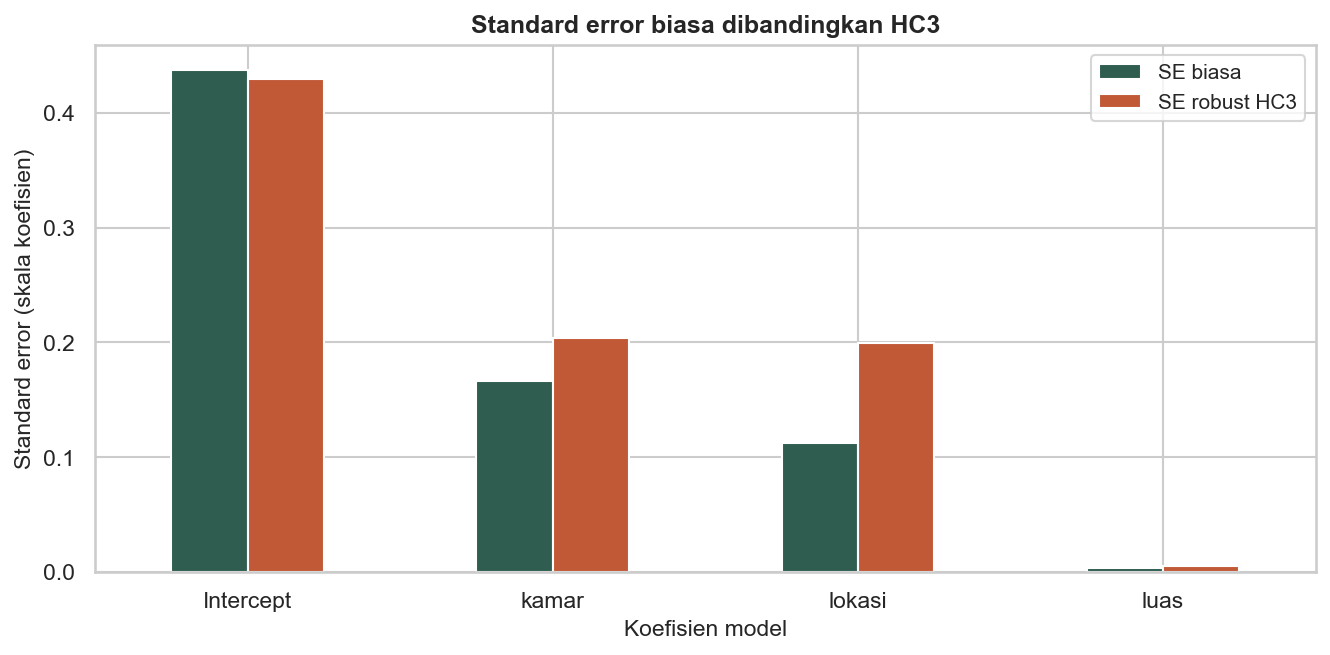

In [32]:
ax = banding[["SE_biasa", "SE_robust"]].plot.bar(figsize=(9, 4.5), rot=0)
ax.set_xlabel("Koefisien model")
ax.set_ylabel("Standard error (skala koefisien)")
ax.set_title("Standard error biasa dibandingkan HC3")
ax.legend(["SE biasa", "SE robust HC3"])
plt.tight_layout()
plt.show()

**Cara membaca:** bandingkan pasangan batang pada koefisien yang sama.
Satuan antarkoefisien dapat berbeda, sehingga tinggi batang tidak menjadi
peringkat pentingnya variabel. HC3 mengoreksi standard error pada model yang
sama; koefisien dan prediksi OLS tetap, sedangkan p-value dapat berubah.

Koefisien tidak berubah, yang berubah hanya standard error dan p-value.
Setelah ini, inferensi memakai kolom robust. Catat juga: kalau kesimpulan
signifikansi berubah karena robust SE, itu temuan yang layak dilaporkan,
bukan sesuatu yang disembunyikan.



## 5. Uji normalitas residual

Normalitas residual dibutuhkan untuk inferensi pada sampel kecil. Data
`latihan_normalitas_1.csv`: harga saham dijelaskan suku bunga, tingkat
pengangguran, dan pertumbuhan PDB.



<!-- kamus_variabel:latihan_normalitas_1.csv -->

### Kenali data: Harga saham dan kondisi makro

**Data:** `data/latihan_normalitas_1.csv`. **Satu baris:** satu pengamatan gabungan harga saham dan indikator makro.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Harga_Saham` | `harga_saham` | Harga penutupan saham pada pengamatan. | Uang per lembar; skala tidak dirinci | Y: target |
| `Tingkat_Suku_Bunga` | `suku_bunga` | Tingkat bunga bank sentral. | Persen | X: penjelas |
| `Tingkat_Pengangguran` | `pengangguran` | Tingkat pengangguran nasional. | Persen | X: penjelas |
| `Pertumbuhan_PDB` | `pdb` | Laju pertumbuhan PDB kuartalan pada contoh sumber. | Persen | X: penjelas |

Berkas tidak memiliki tanggal; jangan mengarang tahun kalender dari nomor baris.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [33]:
saham_makro = pd.read_csv(URL_DATA + "latihan_normalitas_1.csv")
saham_makro = saham_makro.rename(
    columns={
        "Harga_Saham": "harga_saham",
        "Tingkat_Suku_Bunga": "suku_bunga",
        "Tingkat_Pengangguran": "pengangguran",
        "Pertumbuhan_PDB": "pdb",
    }
)

saham_makro.head()

,harga_saham,suku_bunga,pengangguran,pdb
0,150.5,2.5,5.4,2.1
1,148.2,2.6,5.5,2.0
2,155.1,2.4,5.3,2.3
3,160.3,2.2,5.1,2.8
4,145.9,2.8,5.7,1.8


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [34]:
sampel_model_n = saham_makro[
    ["harga_saham", "suku_bunga", "pengangguran", "pdb"]
].dropna()
X_model_n = sampel_model_n[["suku_bunga", "pengangguran", "pdb"]]
y_model_n = sampel_model_n["harga_saham"]

In [35]:
model_n = LinearRegression()
model_n.fit(X_model_n, y_model_n)

prediksi_model_n = pd.Series(model_n.predict(X_model_n), index=y_model_n.index)
residu_model_n = y_model_n - prediksi_model_n

from statsmodels.stats.stattools import jarque_bera

jb, p_jb, skew, kurt = jarque_bera(residu_model_n)
print(f"Jarque-Bera = {jb:.3f}")
print(f"p-value     = {p_jb:.4f}")
print(f"Skewness    = {skew:.3f}, Kurtosis = {kurt:.3f}")


Jarque-Bera = 1.267
p-value     = 0.5307
Skewness    = -0.343, Kurtosis = 2.630


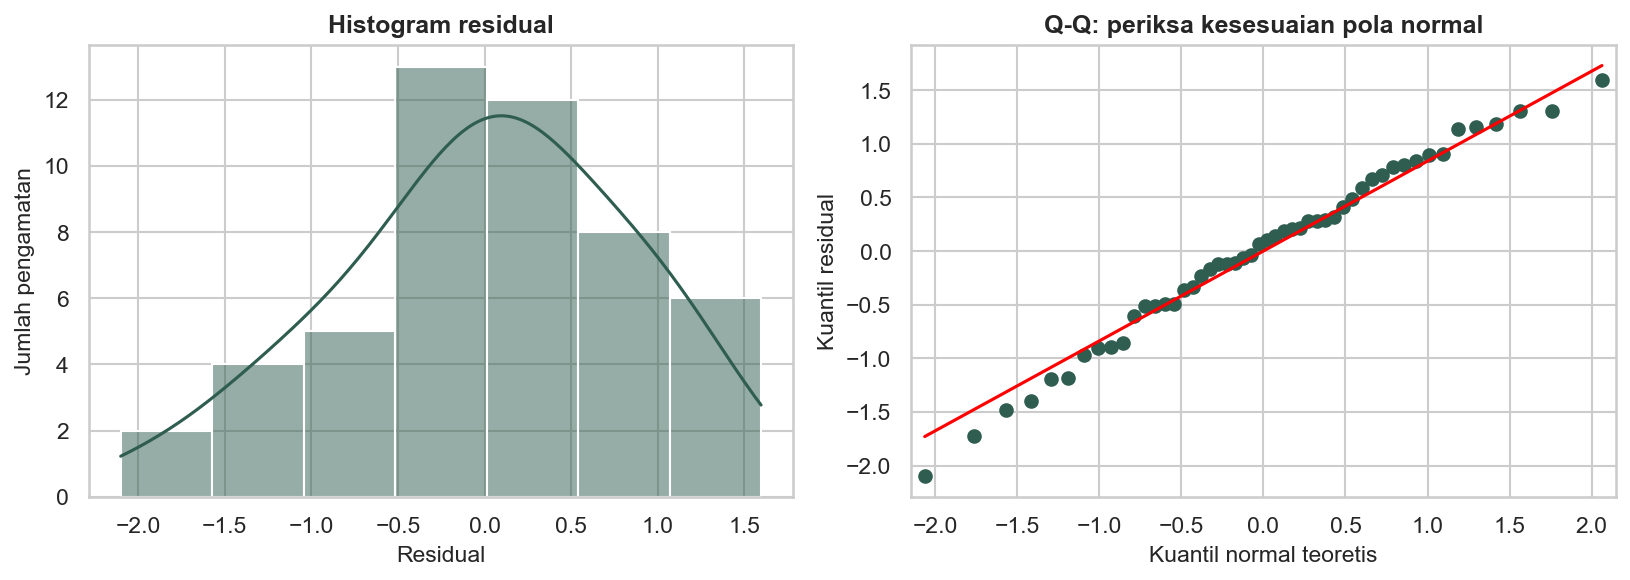

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(residu_model_n, kde=True, ax=axes[0], color="#2F5D50")
axes[0].set_title("Histogram residual")
sm.qqplot(residu_model_n, line="s", ax=axes[1])
axes[1].set_title("Q-Q plot")
axes[0].set(xlabel="Residual", ylabel="Jumlah pengamatan")
axes[1].set(xlabel="Kuantil normal teoretis", ylabel="Kuantil residual", title="Q-Q: periksa kesesuaian pola normal")
plt.tight_layout()
plt.show()


**Baca grafik sebelum lanjut:** Histogram memperlihatkan banyaknya residual pada tiap rentang. Pada Q-Q plot, titik yang mengikuti diagonal lebih sejalan dengan pola normal. Perhatikan ekor dan pencilan, lalu cocokkan dengan hasil uji normalitas; tinggi batang bukan nilai prediksi.

Aturan keputusan: p-value JB di bawah 0,05 = residual tidak normal.
Yang perlu diperiksa kalau normalitas ditolak: outlier, data ekstrem,
atau salah spesifikasi model. Tidak ada batas ukuran sampel yang otomatis
menjamin inferensi aman. Pertimbangkan ketergantungan data, pencilan,
dan beratnya penyimpangan; jangan membuang data hanya agar uji lolos.



## 6. Uji autokorelasi

Autokorelasi = residual periode ini berkorelasi dengan residual periode
sebelumnya. Kasus ini khas data deret waktu. Model OLS masih tak bias,
tapi standard error salah dan p-value terlalu optimistis.

Kita pakai `latihan_dummy_2.csv` (data tahunan PDB dan investasi). Dua
variabel yang sama-sama bergerak sepanjang waktu sering menghasilkan
residual berautokorelasi.



In [37]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Uji autokorelasi memakai model yang sama seperti bagian 2,
# di sini difokuskan ke diagnostik residualnya
model_ar = model_krisis
dw = durbin_watson(residu_model_krisis)
bg_stat, bg_p, _, _ = acorr_breusch_godfrey(uji_model_krisis, nlags=2)

print(f"Durbin-Watson          = {dw:.3f}")
print(f"Breusch-Godfrey p-value = {bg_p:.4f}")


Durbin-Watson          = 1.291
Breusch-Godfrey p-value = 0.1067


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_38068\3342456580.py:8: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_stat, bg_p, _, _ = acorr_breusch_godfrey(uji_model_krisis, nlags=2)


### Periksa urutan residual, lalu baca uji autokorelasi

Dua residual yang berdekatan waktunya dapat mempunyai pola yang sama. Kita lihat urutannya, bukan hanya satu p-value.

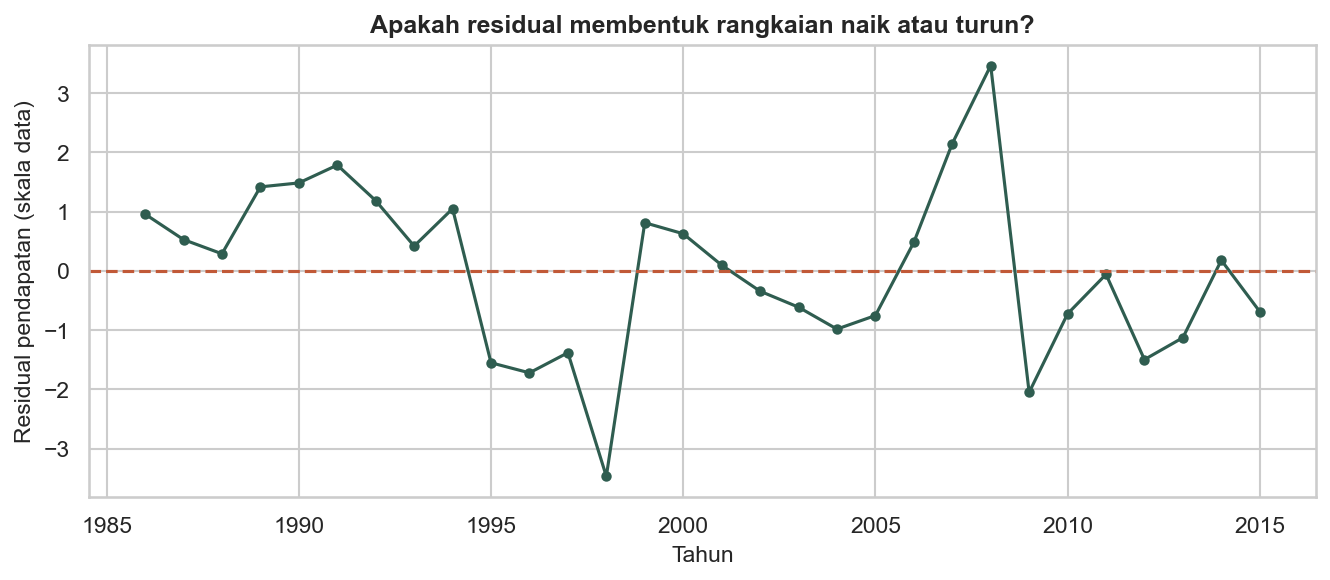

In [38]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(krisis["tahun"], residu_model_krisis, marker="o", markersize=4)
ax.axhline(0, color="#C15937", linestyle="--")
ax.set_xlabel("Tahun")
ax.set_ylabel("Residual pendapatan (skala data)")
ax.set_title("Apakah residual membentuk rangkaian naik atau turun?")
plt.tight_layout()
plt.show()

**Cara membaca:** Rangkaian residual yang lama berada pada sisi yang sama dari nol dapat menjadi petunjuk autokorelasi. Cocokkan pengamatan ini dengan DW dan Breusch–Godfrey; HAC memperbaiki standard error pada spesifikasi yang sama.

Panduan kasar DW: mendekati 2 = aman, di bawah 1,5 = indikasi
autokorelasi positif, di atas 2,5 = autokorelasi negatif. Breusch-Godfrey
lebih fleksibel karena bisa menguji lag berapa saja.

Di data ini buktinya campuran: DW menunjukkan sinyal autokorelasi positif,
tapi Breusch-Godfrey tidak menolak pada taraf 5%. Situasi campuran seperti
ini wajar pada 30 observasi tahunan. Untuk data deret waktu, memakai HAC standard
error adalah asuransi yang murah, dan di bawah terlihat p-value `krisis`
berubah cukup banyak setelah koreksi.

Penanganan praktis: Newey-West standard error (HAC). Di EViews: tab
Options > Newey-West. Di statsmodels: `cov_type="HAC"`.



In [39]:
# Fit ulang model yang sama, kali ini dengan HAC standard error
# Pelengkap inferensi: koreksi standard error, dengan X dan y yang sama.
uji_model_ar_nw = sm.OLS(
    y_model_krisis,
    sm.add_constant(X_model_krisis, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
banding_ar = pd.DataFrame(
    {
        "koefisien": koefisien_model_krisis,
        "SE_biasa": uji_model_krisis.bse,
        "p_biasa": uji_model_krisis.pvalues,
        "SE_HAC": uji_model_ar_nw.bse,
        "p_HAC": uji_model_ar_nw.pvalues,
    }
)
banding_ar


,koefisien,SE_biasa,p_biasa,SE_HAC,p_HAC
Intercept,17.813262,4.751895,0.000897,3.863558,4.015371e-06
investasi,-0.098775,0.116786,0.405395,0.100127,3.238889e-01
krisis,-5.902161,1.494664,0.000534,2.640020,2.537472e-02
suku_bunga,-1.337450,0.288999,0.000090,0.235480,1.349409e-08


## 7. Alur keputusan diagnostik

Ringkasnya, ini yang dilakukan saat memeriksa model:

| Masalah | Deteksi | Penanganan cepat |
|---|---|---|
| Multikolinearitas | VIF > 10 | buang/gabung variabel, tambah sampel |
| Heteroskedastisitas | BP/White/Glejser p < 0,05 | robust SE `HC3` |
| Non-normalitas | JB p < 0,05 | cek outlier, transformasi; n besar relatif aman |
| Autokorelasi | DW jauh dari 2, BG p < 0,05 | Newey-West `HAC` |

Urutan pengujian yang dipakai di materi kuliah: multikolinearitas dulu
(karena menentukan variabel mana yang dipakai), lalu heteroskedastisitas,
normalitas, dan autokorelasi.



## Latihan

1. Multikolinearitas kasus kedua: `latihan_multikolinieritas_2.csv`
   (`konsumsi ~ pendapatan + kekayaan + jml_anggota`). Hitung VIF, buang
   satu variabel dengan VIF tertinggi, lalu hitung VIF sisanya. Kalau
   dua variabel bersaing, pertahankan yang paling relevan secara teori.
   Bandingkan koefisien sebelum dan sesudah pembuangan.
2. Heteroskedastisitas kasus kedua: `hetero_2.csv`
   (`pendapatan ~ pendidikan + pengalaman + usia`). Jalankan uji
   Breusch-Pagan dan White, lalu bandingkan p-value biasa dan robust.
3. Kasus `hetero_1.csv` (`penjualan ~ iklan + salesperson + diskon`)
   melatih melaporkan hipotesis yang ditolak: uji Breusch-Pagan dan
   White di data itu tidak menolak homoskedastis, jadi dugaan "variasi
   penjualan membesar saat iklan tinggi" tidak didukung data. Tulis
   kesimpulan apa adanya, jangan paksakan narasi.
4. Normalitas kasus ketiga: `latihan_normalitas_3.csv`
   (`harga ~ luas_bangunan + jumlah_kamar + usia_rumah`). Tampilkan
   histogram residual dan uji Jarque-Bera.



### Selanjutnya

Selanjutnya: Sesi 4 mengganti jenis variabel Y dari kontinu ke
kategorikal.
